# CSS 基础

选择器进阶 + 背景属性 + 元素显示模式 + 三大特性（前端第 04 天，CSS 第 02 天）


## 课程说明

本篇依据黑马程序员第 04 天资料整理，按选择器进阶、背景相关属性、元素显示模式、CSS 特性、综合案例的顺序展开，最后保留配套选做练习。

资料来自[百度网盘分享](https://pan.baidu.com/s/1Cf1WISQ8Fc15xm7gf0VyBw?pwd=1234)，提取码 `1234`。使用 `day04.rar` 中的 `02-PPT/day04（CSS02-选择器进阶+背景相关属性+元素显示模式+三大特性）v1.0.pdf`（63 页），并核对了 `01-案例` 课堂代码、`03-XMind` 总结和 `04-作业` 配套资料。

封面写“三大特性”，但本日讲义实际讲解继承性、层叠性；优先级只作为判断样式覆盖的前提出现，XMind 也只列出其名称。本篇保留这一范围，不补写优先级计算规则。

普通课堂示例分开列出 CSS 和 HTML：CSS 放在 `<head>` 的 `<style>` 内，HTML 放在 `<body>` 内，保存后用浏览器打开或刷新。综合案例使用与讲义要求一致的配套必做完整代码，并说明与课堂版的差异。代码用于阅读和练习，必要教学图片直接内嵌。


## 1. 选择器进阶

前一天的基础选择器按标签名、类名、ID 等找元素。本节进一步按元素之间的关系、多个条件和鼠标状态选择元素。

| 写法 | 名称 | 选择目标 |
| --- | --- | --- |
| `div p` | 后代选择器 | `div` 内所有层级的 `p` |
| `div > a` | 子代选择器 | 直接位于 `div` 下一层的 `a` |
| `p, div, span` | 并集选择器 | 三组选择结果的集合 |
| `p.box` | 交集选择器 | 同时是 `p` 且有 `box` 类的元素 |
| `a:hover` | hover 伪类选择器 | 鼠标正悬停其上的 `a` |

### 1.1 后代选择器：空格

`选择器1 选择器2` 中间用空格分隔。先找到满足选择器 1 的元素，再到它的后代中寻找满足选择器 2 的元素。

后代包括儿子、孙子及更深的层级，不局限于直接下一层。最终设置样式的是后面选择器所匹配的后代元素。

课堂文件 `01-选择器-后代.html`：

CSS（放在 `<style>` 内）：

```css
/* 找到div的儿子p设置文字颜色是红色 */
/* 父选择器   后代选择器 {} */
div p {
    color: red;
}
```

HTML（放在 `<body>` 内）：

```html
<!-- 后代: 儿子, 孙子, 重孙子..... -->
<p>这是一个p标签</p>
<div>
    <p>这是div的儿子p</p>
</div>
```

外面的 `p` 不符合“位于 div 内”的条件，保持默认颜色；`div` 内的 `p` 显示红色。若再往 `div` 中嵌套容器，容器内的 `p` 仍能被 `div p` 选中。


### 1.2 子代选择器：`>`

`选择器1 > 选择器2` 只在前者的直接子元素中找后者，不继续向孙子等层级查找。

课堂文件 `02-选择器-子代.html`：

CSS（放在 `<style>` 内）：

```css
/* 空格隔开的是后代, 儿子,孙子,重孙子 */
/* div a {
    color: red;
} */

/* 只想选中儿子a */
/* div的儿子a文字颜色是红色 */
div>a {
    color: red;
}
```

HTML（放在 `<body>` 内）：

```html
<div>
    父级
    <a href="#">这是div里面的a</a>
    <p>
        <a href="#">这是div里面的p里面的a</a>
    </p>
</div>
```

`div` 直接包含的第一个链接显示红色；`p` 内的第二个链接属于 `div` 的孙子，没有被 `div>a` 选中，保持浏览器的链接颜色。

要对比两种关系，先注释掉 `div>a` 这一规则，再启用文件中注释的 `div a`：此时两个链接都变红。`>` 两侧是否留空格不改变含义，排版时写成 `div > a` 更清楚。


### 1.3 并集选择器：逗号

多个选择器用英文逗号 `,` 分隔，给多组元素设置相同的样式。每组可以是基础选择器，也可以是复合选择器；通常一行写一个，便于阅读。

课堂文件 `03-选择器-并集.html`：

CSS（放在 `<style>` 内）：

```css
/* p div span h1 文字颜色是红色 */
/* 选择器1, 选择器2 {} */
p, 
div, 
span, 
h1 {
    color: red;
}
```

HTML（放在 `<body>` 内）：

```html
<p>ppp</p>
<div>div</div>
<span>span</span>
<h1>h1</h1>

<h2>h2</h2>
```

`p`、`div`、`span`、`h1` 的文字都变红，未列出的 `h2` 不受这条规则影响。

> `p, div` 表示“p 和 div 都选”；`div p` 表示“只选 div 里面的 p”。逗号和空格改变的是选择关系，不能互换。


### 1.4 交集选择器：紧挨着

交集遵循“既……又……”：一个元素要同时满足所有条件才会被选中。条件之间紧挨着，不加空格或逗号；若包含标签选择器，标签名放在最前面。

课堂文件 `04-选择器-交集.html` 保留了多种对比写法：

CSS（放在 `<style>` 内）：

```css
/* p {
    color: red;
} */

/* .box {
    color: red;
} */

/* 必须是p标签,而且添加了box类 */
/* p.box {
    color: red;
} */
/* #dilireba {
    color: red;
} */

.box1 {
    color: green;
}
```

HTML（放在 `<body>` 内）：

```html
<!-- 找到第一个p,带box类的, 设置文字颜色是红色 -->
<p class="box box1" id="dilireba">这是p标签:box</p>
<p class="box">这是p标签:box</p>
<p>pppppp</p>
<div class="box">这是div标签:box</div>
```

文件当前只启用了 `.box1`，所以第一个 `p` 是绿色，其他元素没有新增颜色。练习交集时，先注释掉 `.box1` 的规则，再取消 `p.box` 规则的注释：前两个 `p` 变红，普通 `p` 和带 `box` 类的 `div` 都不符合完整条件。

| 写法 | 结果 |
| --- | --- |
| `p` | 所有 `p` |
| `.box` | 所有使用 `box` 类的元素 |
| `p.box` | 使用 `box` 类的 `p` |
| `.box.box1` | 同时使用两个类的同一个元素 |

**原代码注释辨析：**文件中有“找到第一个 p”的说明，但 `p.box` 会同时选中两个带 `box` 类的 `p`，并不限制为第一个。


### 1.5 hover 伪类：鼠标悬停状态

`选择器:hover` 在鼠标悬停到对应元素时应用样式，移开后恢复未悬停时的样式。冒号用英文 `:`。

课堂文件 `05-选择器-伪类.html`：

CSS（放在 `<style>` 内）：

```css
/* 悬停的时候文字颜色是红色 */
a:hover {
    color: red;
    background-color: green;
}

/* 用户鼠标悬停到div的时候, 文字是绿色 */
div:hover {
    color: green;
}
```

HTML（放在 `<body>` 内）：

```html
<a href="#">这是超链接</a>
<!-- 任何标签都可以添加伪类, 任何一个标签都可以鼠标悬停 -->
<div>div</div>
```

鼠标移到链接上，链接文字变红、背景变绿；移到 `div` 上，文字变绿。hover 不只用于链接，也可以用于本节的其他元素，无需编写 JavaScript 就能完成这种样式变化。


### 1.6 Emmet：用缩写快速生成代码

Emmet 是编辑器中的代码缩写功能，写法借用了标签、类、ID 和嵌套关系。缩写展开后得到 HTML 或 CSS 源码。

**操作补充：**在支持 Emmet 的编辑器（如 VS Code）中，先进入 HTML 或 CSS 的相应编辑位置，再输入缩写并按 `Tab` 展开，或选择对应补全项；这些缩写不直接交给浏览器执行。

| 缩写 | 生成的内容 |
| --- | --- |
| `div` | `<div></div>` |
| `.red` | `<div class="red"></div>`，省略标签时本例默认生成 div |
| `p.box` | `<p class="box"></p>` |
| `#one` | `<div id="one"></div>` |
| `p.red#one` | `<p class="red" id="one"></p>` |
| `div+p` | 同级的 `div` 与 `p` |
| `ul>li` | `ul` 内部嵌套一个 `li` |
| `ul>li{我是li的内容}` | 在 `li` 中写入花括号内的文字 |
| `ul>li*3` | 一个 `ul` 内生成三个 `li` |
| `ul>li{111}*3` | 三个 `li` 都包含文字 `111` |
| `ul>li{$}*3` | `$` 生成连续编号，三个 `li` 分别包含 1、2、3 |

课堂文件 `06-emmet语法.html` 中，`ul>li{$}*3` 展开的结果：

```html
<ul>
    <li>1</li>
    <li>2</li>
    <li>3</li>
</ul>
```

CSS 也能用属性缩写。课程以属性单词首字母提示输入，如 `fz` 对应 `font-size`、`fw` 对应 `font-weight`、`w` 对应 `width`、`h` 对应 `height`、`bgc` 对应 `background-color`、`lh` 对应 `line-height`。

课堂缩写 `w300+h200+bgc` 可以先生成宽 300px、高 200px 和背景颜色声明，再填写颜色 `pink`。文件中完成后的三条声明是：

```css
width: 300px;
height: 200px;
background-color: pink;
```

**练习提醒：**该演示文件还留有未填写值的声明，以及两个 `id="box"` 的独立生成示例。前者是编辑过程中的占位内容，后者用于展示不同缩写；整理成实际页面时应填好属性值，并保证文档中的 ID 唯一。


## 2. 背景相关属性

背景给元素增加颜色或图片装饰。本节先分别设置各项属性，再合并为 `background`。

### 2.1 背景颜色：`background-color`

取值延续上一节的关键字、RGB、RGBA、十六进制颜色。默认背景透明，可以用 `transparent` 或 `rgba(0, 0, 0, 0)` 表达。

背景颜色不改变元素的宽高，但可以让元素的范围与位置更明显，所以课程常先加背景色检查布局。

课堂文件 `07-背景-背景色.html`：

CSS（放在 `<style>` 内）：

```css
div {
    width: 400px;
    height: 400px;
    /* background-color: pink; */
    /* background-color: #ccc; */
    /* 红绿蓝三原色, a是透明度0-1 */
    /* background-color: rgba(0, 0, 0, 0.5); */
    background-color: rgba(0, 0, 0, .5);
}
```

HTML（放在 `<body>` 内）：

```html
<div>div</div>
```

可看到 400px × 400px 的半透明黑色背景，`rgba(..., .5)` 中的 `.5` 与 `0.5` 相同。背景取值为透明时，下方内容或父元素背景会透出来。


### 2.2 背景图片：`background-image`

用 `url(图片路径)` 指定图片，路径可以加引号，也可以使用本例这样不加引号的写法。课堂文件 `08-背景-背景图.html`：

CSS（放在 `<style>` 内）：

```css
div {
    width: 400px;
    height: 400px;
    background-color: pink;
    background-image: url(./images/1.jpg);
}
```

HTML（放在 `<body>` 内）：

```html
<div>文字</div>
```

练习时，将课堂资料的 `images/1.jpg` 放在 HTML 同级的 `images` 目录内。原图为 200px × 200px，盒子为 400px × 400px，图片默认沿水平和垂直方向重复铺满背景，文字仍作为 HTML 内容显示在上面。

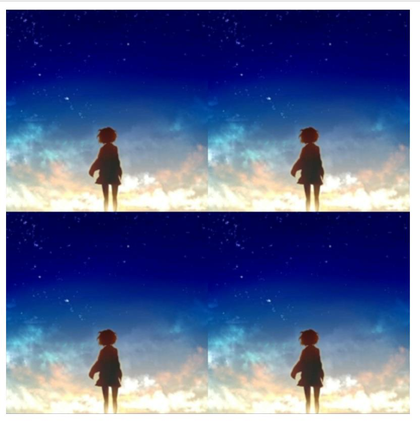

> 背景图片只是 CSS 装饰，不会像 HTML 内容一样撑开盒子。本例专门设置宽高；若空 div 没有高度，图片即使路径正确，也可能看不到。

**补充：**本课 CSS 写在 HTML 内，所以相对路径从 HTML 所在目录出发；若移到外部 `.css` 文件，`url()` 的相对路径从该 CSS 文件所在目录计算。


### 2.3 背景平铺：`background-repeat`

| 值 | 效果 |
| --- | --- |
| `repeat` | 默认值，水平和垂直方向都平铺 |
| `no-repeat` | 不平铺，只显示一张 |
| `repeat-x` | 沿水平方向平铺 |
| `repeat-y` | 沿垂直方向平铺 |

课堂文件 `09-背景-背景平铺.html` 把四种写法都留在注释中：

CSS（放在 `<style>` 内）：

```css
div {
    width: 400px;
    height: 400px;
    background-color: pink;
    background-image: url(./images/1.jpg);
    /* background-repeat: repeat; */
    /* 不平铺: 图片只显示一个 */
    /* background-repeat: no-repeat; */
    /* background-repeat: repeat-x; */
    /* background-repeat: repeat-y; */
}
```

HTML（放在 `<body>` 内）：

```html
<div>文字</div>
```

当前没有启用任何 `background-repeat` 声明，因此仍是默认平铺。每次只启用其中一条来观察：`no-repeat` 时只在左上角显示一张，`repeat-x` 时横向成一排，`repeat-y` 时纵向成一列，未被不透明图片遮住的区域显示背景色。

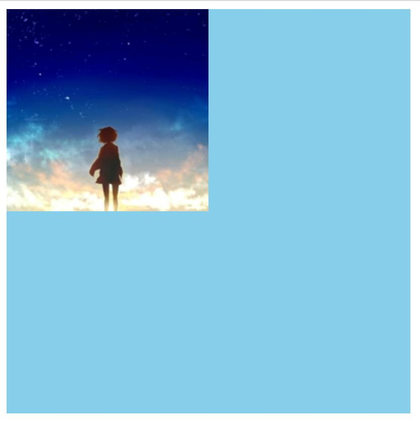

讲义示意图使用蓝色底，课堂代码使用粉色底；这里对比的是平铺规则，保持各自资料的原始颜色。


### 2.4 背景位置：`background-position`

课程的两值写法是 `background-position: 水平位置 垂直位置;`，可以用方位词或像素坐标。

| 方向 | 方位词 |
| --- | --- |
| 水平 | `left`、`center`、`right` |
| 垂直 | `top`、`center`、`bottom` |

两个方向组合得到左上、上中、右上、左中、正中、右中、左下、下中、右下九个位置。例如 `right bottom` 是右下，`center center` 是正中，单写 `center` 也表示正中。

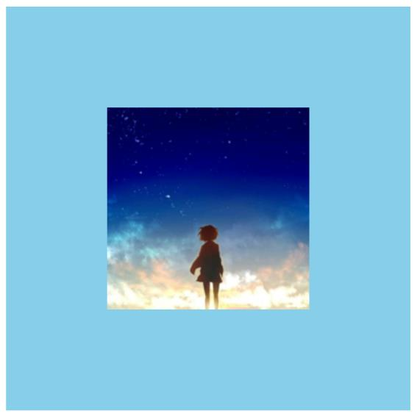

像素坐标以本课盒子左上角为原点 `(0, 0)`：水平向右为正，垂直向下为正。用两个像素值时，将图片左上角移到对应坐标；负数表示向左或向上移动。

课堂文件 `10-背景-背景位置.html`：

CSS（放在 `<style>` 内）：

```css
div {
    width: 400px;
    height: 400px;
    background-color: pink;
    background-image: url(./images/1.jpg);
    background-repeat: no-repeat;
    /* background-position: right 0; */
    /* background-position: right bottom; */
    /* background-position: center center; */
    /* background-position: center; */
    /* background-position: 50px 0; */
    /* background-position: 50px 100px; */
    background-position: -50px -100px;

    /* 正数: 向右向下移动; 负数:向左向上移动 */
    /* 注意: 背景色和背景图只显示在盒子里面 */
}
```

HTML（放在 `<body>` 内）：

```html
<div>文字</div>
```

当前启用 `-50px -100px`：图片向左移 50px、向上移 100px，移出盒子范围的部分不会显示。先注释这条，再启用注释里的不同位置来比较。

| 文件中的写法 | 应看到的位置 |
| --- | --- |
| `right 0` | 水平靠右，垂直在顶部 |
| `right bottom` | 右下 |
| `center center` 或 `center` | 正中 |
| `50px 0` | 图片左上角向右 50px，垂直不移动 |
| `50px 100px` | 图片左上角向右 50px、向下 100px |
| `-50px -100px` | 图片左上角向左 50px、向上 100px |

方位词和坐标可以混用，例如 `right 0`。本课混合或数值写法按“水平、垂直”顺序填写；两个明确方向的关键词如 `bottom center` 和 `center bottom` 可以表达同一位置，但两个数值不能随意交换。


### 2.5 背景属性连写：`background`

课程推荐按 `color image repeat position` 的顺序写，各部分之间用空格：

```css
background: pink url(./images/1.jpg) no-repeat center bottom;
```

这相当于背景粉色、使用指定图片、不平铺、放在底部中央。所需部分可以省略；省略的相关属性会回到默认值，不是保留之前的设置。

课堂文件 `11-背景-复合属性.html`：

CSS（放在 `<style>` 内）：

```css
div {
    width: 400px;
    height: 400px;
    /* 不分先后顺序 背景色  背景图  背景图平铺  背景图位置 */
    /* background: pink url(./images/1.jpg) no-repeat center bottom; */
    /* 背景图位置如果是英文单词可以颠倒顺序 */
    background: pink url(./images/1.jpg) no-repeat bottom center ;

    /* 测试背景图位置如果是数值 不要颠倒顺序 */
    /* 水平50px, 垂直100px */
    /* background: pink url(./images/1.jpg) no-repeat 50px 100px; */
    background: pink url(./images/1.jpg) no-repeat 100px 50px;


}
```

HTML（放在 `<body>` 内）：

```html
<div></div>
```

文件有两条生效的 `background`。后面的 `100px 50px` 覆盖前面的 `bottom center`，所以最终图片从左上角向右 100px、向下 50px。练习第一条时，应先注释掉最后一条，避免观察到的仍是后面的效果。

若单独属性与连写一起使用，需要把单独的声明放在连写后面，或直接把该值包含进连写。例如本节若先写 `background-repeat: no-repeat;`，随后只写 `background: url(...);`，平铺会被重置为默认 `repeat`。

课程还指出：在 PC 案例里，若盒子尺寸与背景图片尺寸一致，可以只写 `background: url(...);`。本例五彩导航的素材正是 120px × 58px，重复背景不会在这一范围内产生额外完整图案。

### 2.6 `img` 与背景图片的区别

| 方法 | 如何显示图片 | 尺寸特点 |
| --- | --- | --- |
| `img` 标签 | 作为 HTML 内容 | 不另设宽高时，通常按图片原始尺寸显示 |
| `div` 加背景图片 | 作为元素背景装饰 | 图片不能撑开 div，需由宽高或实际内容建立可见范围 |

课堂图片为 `images/1.jpg`，可分别放入 HTML 与 CSS 对比：

```html
<img src="./images/1.jpg" alt="">
<div></div>
```

```css
div {
    width: 200px;
    height: 200px;
    background-image: url(./images/1.jpg);
}
```

上面是按讲义第 32 页说明整理的最小对比写法。删除空 div 的 `height` 后，背景图不会替它撑出 200px 高度；`img` 自身仍能显示图片。


## 3. 元素显示模式

元素的显示模式决定它是否另起一行、尺寸如何形成、宽高设置是否生效。本节讨论普通文档流中的三种常见模式。

| 模式 | 一行如何排列 | 默认尺寸 | 是否可设置宽高 | 常见标签 |
| --- | --- | --- | --- | --- |
| 块级 | 独占一行 | 宽度占父容器可用宽度，高度由内容形成 | 可以 | `div`、`p`、`h1`～`h6`、`ul`、`li`、`dl`、`dt`、`dd`、`form`、`header`、`nav`、`footer` |
| 行内 | 一行可排列多个，空间不足会换行 | 由内容形成 | 普通非替换行内元素不生效 | `a`、`span`、`b`、`u`、`i`、`s`、`strong`、`ins`、`em`、`del` |
| 行内块 | 一行可排列多个，空间不足会换行 | 未指定尺寸时由内容或控件默认尺寸形成 | 可以 | 本课以 `input`、`textarea`、`button`、`select` 等说明 |

### 3.1 块级元素

`div` 默认是块级元素：即使设置较小宽度，相邻块级元素通常也分别占一行。用 Chrome 检查元素，在 **Computed（计算样式）** 中搜索 `display`，可以查看当前显示模式。

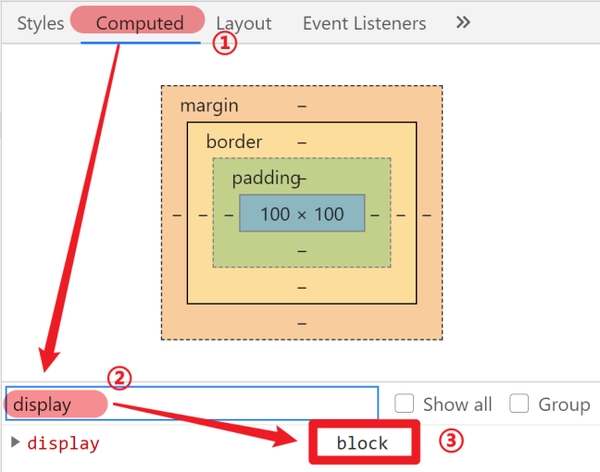

课堂文件 `12-显示模式-块.html` 已经加入显示模式转换：

CSS（放在 `<style>` 内）：

```css
/* 块: 独占一行; 宽度默认是父级100%; 添加宽度都生效 */
div {
    width: 300px;
    height: 300px;
    background-color: pink;

    /* 行内块 */
    /* display: inline-block; */

    /* 行内 */
    display: inline;
}
```

HTML（放在 `<body>` 内）：

```html
<div>11111</div>
<div>22222</div>
```

文件当前启用 `display: inline;`，所以两个 div 按行内方式排列，300px 宽高不再按块级盒子生效。先注释这条声明，观察默认状态：两个粉色 300px × 300px 盒子各占一行。再启用注释中的 `display: inline-block;`，观察两个盒子在空间足够时同行排列、宽高仍有效。


### 3.2 行内元素

`a`、`span` 等普通行内元素不独占一行，宽度随内容形成。对这类元素直接填写 `width`、`height`，不会得到对应尺寸的矩形盒子。

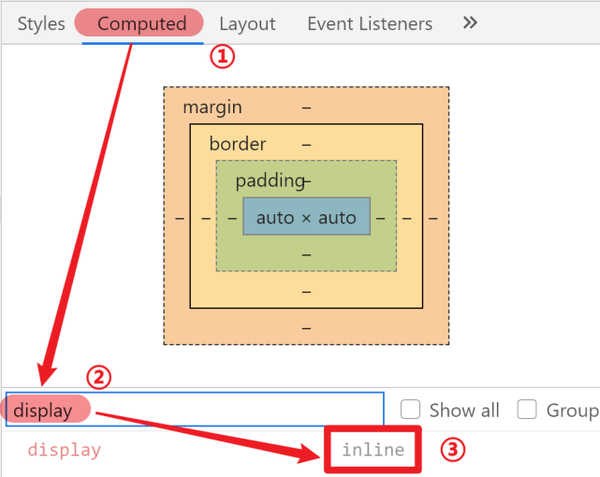

课堂文件 `13-显示模式-行内.html`：

CSS（放在 `<style>` 内）：

```css
/* 行内: 不换行; 设置宽高不生效; 尺寸和内容的大小相同 */
span {
    width: 300px;
    height: 300px;
    background-color: pink;

    /* 行内块 */
    /* display: inline-block; */

    /* 块 */
    display: block;
}
```

HTML（放在 `<body>` 内）：

```html
<span>span</span>
<span>span</span>
```

文件当前启用 `display: block;`，因此两个 span 都变成 300px × 300px 的块，各占一行。先注释这条声明，观察默认行内状态：span 同行显示，粉色背景围绕文字，300px 宽高不生效。再切换为 `inline-block`，比较宽高有效且仍可同行的状态。


### 3.3 行内块元素，以及图片的特殊情况

行内块兼有本课两种需求：既可以一行排多个，也可以设置宽高。

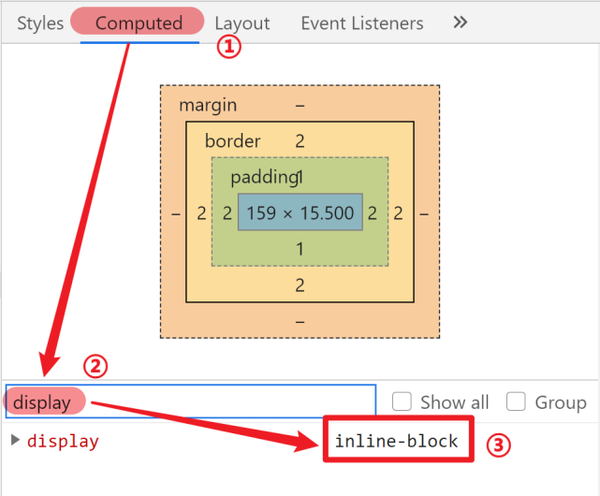

课堂文件 `14-显示模式-行内块.html` 通过图片观察这两个特点：

CSS（放在 `<style>` 内）：

```css
/* 行内块: 一行显示多个; 加宽高生效 */
img {
    width: 100px;
    height: 100px;
}
```

HTML（放在 `<body>` 内）：

```html
<img src="./images/1.jpg" alt="">
<img src="./images/1.jpg" alt="">
```

两张图片在空间足够时同行显示，每张尺寸为 100px × 100px。

> 讲义特别说明：`img` 有这里介绍的行内块式表现，但 Chrome 中默认 `display` 通常显示为 `inline`。不要为了符合课堂分类而把它的计算样式写成 `inline-block`。

**补充：**图片是“替换元素”，浏览器用外部图片替代其内容，所以即使显示模式为 `inline` 也能设置宽高。前面“行内元素宽高无效”的规则主要用于 `span`、普通 `a` 等非替换行内元素。表单控件的具体默认 `display` 可能因控件和浏览器不同，判断时查看计算样式。


### 3.4 用 `display` 转换显示模式

转换的目的是让现有元素符合布局需求，而不必改变它的 HTML 含义。例如导航链接仍用 `a`，但需要设置宽高、形成可点击的矩形区域。

| 属性 | 转换结果 | 本课建议 |
| --- | --- | --- |
| `display: block;` | 块级 | 常用，例如纵向导航 |
| `display: inline-block;` | 行内块 | 常用，例如横向导航 |
| `display: inline;` | 行内 | 本课较少使用，主要用于对比 |

前面两个课堂文件已经提供了切换位置。每次只保留目标 `display` 声明，再刷新并检查：元素是否换行、宽高是否有效、Computed 中显示的值是否与设置一致。


### 3.5 HTML 嵌套规范

课程把块级元素作为大容器，可在合适的容器中放文字、块级、行内、行内块等内容；但 HTML 标签各自还有嵌套规则，不能只凭显示模式决定是否合法。

本课重点是：`p` 内不要嵌套 `div`、另一个 `p` 或 `h1`～`h6`；`a` 内不能再嵌套 `a`。

课堂文件 `15-拓展-标签嵌套.html` 是错误嵌套演示，原代码如下：

```html
<!-- p 和 h标题不能相互嵌套 -->
<!-- <p>
    <h1>一级标题</h1>
</p> -->
<!-- p里面不能包含div -->
<p>
    <div>divdiv</div>
</p>
```

它不是推荐的页面结构。浏览器解析时会自动结束前面的 p，所以在 Elements 中看到的结构可能与输入的缩进不一致。若想包住一个 div，应改用允许这种内容的容器，例如：

```html
<div>
    <div>divdiv</div>
</div>
```

**补充：**原课把“a 内可以嵌套任意元素”作为简化说明；实际也不能嵌套其他交互控件。嵌套应遵循标签的内容规则，改 `display` 不会改变 HTML 规则。


### 3.6 居中方法再整理

上一节的居中方法现在可以结合显示模式选择：

| 目标 | 设置 | 设置给谁 | 本课的条件 |
| --- | --- | --- | --- |
| 文字、行内内容、行内块水平居中 | `text-align: center;` | 它们所在的父容器 | 父容器要有可供对齐的空间 |
| 块级盒子本身水平居中 | `margin: 0 auto;` | 当前盒子 | 本课使用固定宽度，父容器有剩余空间 |
| 单行文字垂直居中 | 行高等于文字容器高度 | 文字所在容器 | 适用于单行文字 |

例如后面的横向导航把 a 转为行内块后，给 a 设置 `text-align: center;` 是让每个按钮内部的文字居中。若要让一整排按钮在父盒子里居中，则给这个父盒子设置 `text-align: center;`，两者设置对象不同。


## 4. CSS 特性

### 4.1 继承性：子元素沿用父元素的部分样式

父元素的某些样式能由子元素继承，减少逐个标签重复设置的代码。本课列出的常见可继承属性包括：

| 类别 | 属性 |
| --- | --- |
| 文字颜色 | `color` |
| 字体 | `font-style`、`font-weight`、`font-size`、`font-family` |
| 文本 | `text-indent`、`text-align` |
| 行高 | `line-height` |

课堂文件 `16-特性-继承性.html`：

CSS（放在 `<style>` 内）：

```css
/* 控制文字的属性都能继承; 不是控制文字的都不能继承 */
div {
    color: red;
    font-size: 30px;
    height: 300px;
}
```

HTML（放在 `<body>` 内）：

```html
<div>
    这是div标签里面的文字
    <span>这是div里面的span</span>
</div>
```

div 内的文字和 span 中的文字都显示为红色、30px。div 的 `height: 300px;` 没有让 span 也继承同样高度。

在 Chrome 中选中子元素，在 Styles 的 **Inherited from ...** 区域查看祖先的样式，区分实际继承的属性与灰显的非继承属性：

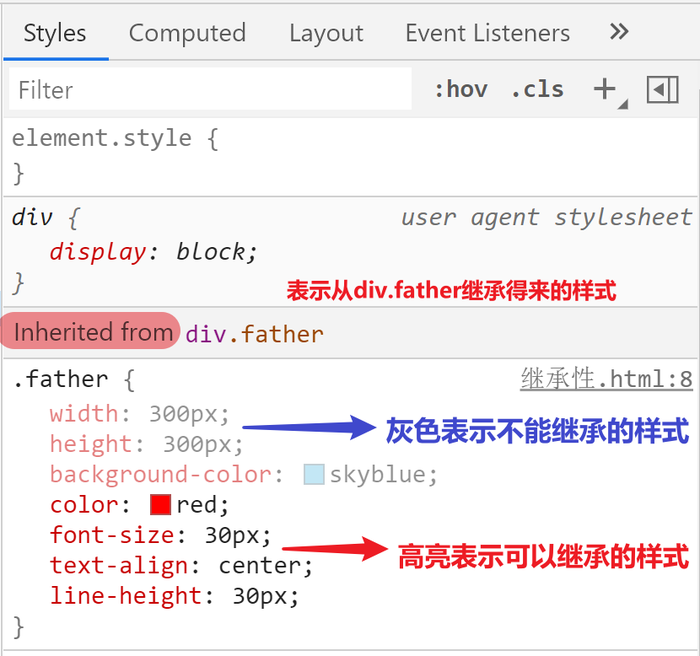

**原资料范围说明：**课堂代码用“控制文字的都能继承”作记忆提示，不能把它扩展为所有文字相关属性的通则。这里以讲义列出的属性为准；如上一节的 `text-decoration` 就不属于默认继承属性。

### 4.2 继承的应用

课程给出两个常见应用：

```css
ul {
    list-style: none;
}

body {
    font-size: 16px;
}
```

把 `list-style: none;` 设置给 ul，可以让内部列表项不再显示默认小圆点；给 body 设置字号，为继承普通正文的元素提供统一基准，减少对浏览器默认字号的依赖。标题和某些控件可能有自己的样式，仍需按实际效果检查。

**XMind 辨析：**总结中提到“div 宽度有继承的效果”。普通块级 div 默认占满父容器的可用宽度，视觉上像沿用了父宽度，但这不等于 `width` 被继承；`width`、`height`、背景颜色默认都不继承。


### 4.3 为什么链接颜色、标题字号没有直接沿用父元素

浏览器为一些元素提供了默认样式：链接有默认颜色，标题有默认字号。继承机制仍存在，但这些元素自身的声明会使最终效果与父元素不同。

课堂文件 `17-特性-继承性-注意.html`：

CSS（放在 `<style>` 内）：

```css
div {
    color: red;
    font-size: 12px;
}

a {
    color: red;
}
```

HTML（放在 `<body>` 内）：

```html
<div>
    <a href="#">超链接</a>
    <h1>一级标题</h1>
</div>
```

文件已经给 a 直接设置了红色，所以最终链接为红色。若注释掉 `a { color: red; }`，只保留父 div 的红色，会看到链接采用浏览器的默认链接颜色；h1 也不会直接显示为普通的 12px 正文大小。

**补充：**更准确地说，元素自身有可用声明时，该属性不会直接采用父元素的继承值；h1 的默认相对字号还可能以父字号为基准计算，所以“没有直接沿用 12px”不等于完全不受父字号影响。遇到差异先检查该元素本身的 Styles 和 Computed。


### 4.4 层叠性：样式叠加与覆盖

多条规则作用于同一个元素时，设置不同属性可以共同生效；同一个属性发生冲突时，需要决定最终取值。

课堂文件 `18-特性-层叠性.html`：

CSS（放在 `<style>` 内）：

```css
div {
    color: red;
    color: green;
}

.box {
    font-size: 30px;
}
```

HTML（放在 `<body>` 内）：

```html
<div class="box">文字</div>
```

div 的两条颜色声明中，后面的 green 覆盖前面的 red；`.box` 另设字号 30px，与颜色共同生效。因此最终显示绿色、30px 的文字。

> 课程强调：只有在选择器优先级相同等可比较的条件下，才用书写先后判断谁覆盖谁。不能把“最后写的一定生效”用于所有规则冲突；本日不展开优先级计算。

### 4.5 XMind 中的调试查错流程

1. 右击页面选择“检查”，在 Elements 中选中出问题的元素。
2. 查看 Styles 是否出现自己写的选择器。没有时，先查样式表是否正确引入，再核对选择器的单词、类名和嵌套关系是否匹配。
3. 选择器出现但样式无效时，查看声明是否有删除线：检查是否被停用、注释或覆盖。
4. 出现警告小三角时，核对属性名、属性值、中文标点，以及相邻声明之间缺失的分号。
5. 用 Computed 查看最终显示模式或属性值，确认效果后回源文件保存修改。

第 2 步的样式表检查是操作补充；其余顺序沿用配套总结。与上一节一样，调试工具的临时修改不会自动写回源文件。


## 5. 综合案例

### 5.1 普通导航

目标是让五个链接横向排列成同样大小的矩形按钮，默认红色背景、白色文字，悬停时背景变橙色。

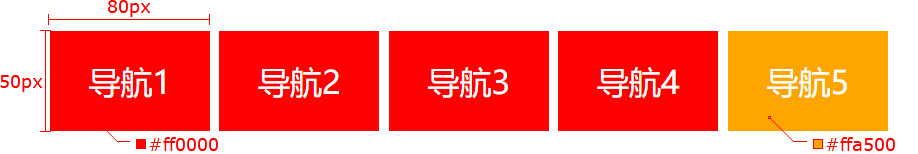

实现顺序：

1. 用 `a{导航$}*5` 生成五个链接，保留 a 的点击跳转语义。
2. a 默认是普通行内元素，先设置 `display: inline-block;`，让宽 80px、高 50px 生效，同时允许同行排列。
3. 设置红色背景、白色文字，去掉链接下划线。
4. `text-align: center;` 让按钮内部文字水平居中，`line-height: 50px;` 让单行文字垂直居中。
5. 写 `a:hover`，将背景改为橙色。

配套必做文件 `01-（案例）综合案例1-普通导航案例.html` 完整代码：

```html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    a {
      width: 80px;
      height: 50px;
      background-color: red;
      /* 转换成行内块元素 */
      display: inline-block;
      /* 文本水平居中 */
      text-align: center;
      /* 文本垂直居中 */
      line-height: 50px;
      /* 文字文本修饰 */
      text-decoration: none;
      color: #fff;
    }

    a:hover {
      background-color: orange;
    }

  </style>
</head>
<body>
  <!-- a{导航$}*5 -->

  <a href="#">导航1</a>
  <a href="#">导航2</a>
  <a href="#">导航3</a>
  <a href="#">导航4</a>
  <a href="#">导航5</a>
</body>
</html>
```

保存后打开或刷新，检查五个按钮尺寸、文字居中和下划线；逐个悬停，确认只有当前按钮变为橙色，移开恢复红色。`red` 对应图中的 `#ff0000`，`orange` 对应 `#ffa500`。

**资料版本差异：**课堂文件 `19-综合案例1.html` 使用 100px 宽，讲义第 59 页标注及配套必做代码使用 80px；本篇完整代码采用与讲义一致的 80px。课堂注释还提示可以用 `Alt + Shift + 鼠标左键单击` 创建多个光标，同时修改多行文字，具体按编辑器配置操作。

**观察补充：**源代码中 a 之间有换行和空格，行内块之间可能显示小间隙，这是本案例的正常现象；本节先按原课实现。


### 5.2 五彩导航

在普通导航基础上，四个链接分别使用不同背景图片；悬停时替换为另一张图片，按钮大小不变。

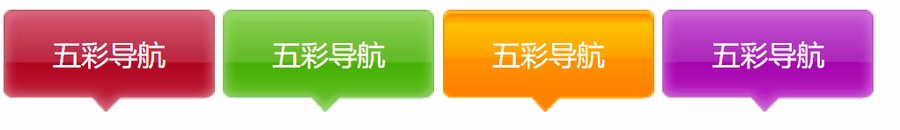

资料中的 `bg1.png`～`bg8.png` 均为 **120px × 58px**。每个按钮也设置为这一尺寸；先用标签选择器统一 a 的显示模式、宽高、文字样式，再用类选择器区分背景。

| 类名 | 默认背景 | hover 背景 |
| --- | --- | --- |
| `.one` | `images/bg1.png` | `images/bg5.png` |
| `.two` | `images/bg2.png` | `images/bg6.png` |
| `.three` | `images/bg3.png` | `images/bg7.png` |
| `.four` | `images/bg4.png` | `images/bg8.png` |

练习时，将这八张素材放在 HTML 同级的 `images` 文件夹，保持路径不变。配套必做文件 `02-（案例）综合案例2-五彩导航案例.html`：

```html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    a {
      width: 120px;
      height: 58px;
      background-color: pink;

      /* 转换成行内块元素 */
      display: inline-block;
      /* 文本水平居中 */
      text-align: center;
      /* 文本垂直居中 */
      line-height: 50px;
      /* 文字文本修饰 */
      text-decoration: none;
      color: #fff;
    }

    .one {
      background: url('./images/bg1.png');
    }
    .two {
      background: url('./images/bg2.png');
    }
    .three {
      background: url('./images/bg3.png');
    }
    .four {
      background: url('./images/bg4.png');
    }

    .one:hover {
      background: url('./images/bg5.png');
    }
    .two:hover {
      background: url('./images/bg6.png');
    }
    .three:hover {
      background: url('./images/bg7.png');
    }
    .four:hover {
      background: url('./images/bg8.png');
    }

  </style>
</head>
<body>
  <a href="#" class="one">五彩导航</a>
  <a href="#" class="two">五彩导航</a>
  <a href="#" class="three">五彩导航</a>
  <a href="#" class="four">五彩导航</a>
</body>
</html>
```

这里链接总高 58px，但行高用 **50px**，是因为素材下方还有小尖角，文字要在上方矩形区域居中；不是把上一案例的“行高等于容器高度”机械地改成 58px。

默认四张图与链接尺寸相同，所以使用 `background: url(...);` 即可。逐个悬停，确认只替换对应按钮的背景，文字、尺寸和排列保持一致。若图片不出现，先检查相对路径和文件名；若按钮只围住文字，检查 `display: inline-block;`。

**资料版本差异：**课堂文件 `20-综合案例2.html` 用 `background-image` 换图片，保留 a 的粉色背景；配套必做版使用 `background` 连写，会把背景色重置为透明。本篇保留必做版，正好对应前面的连写重置规则，素材透明区域会透出页面底色。


## 6. 配套练习

资料将上面两个导航列为必做案例，另外提供三个选做练习。下面继续使用当天已经讲过的显示模式、背景、后代选择器和 hover。

### 6.1 购物车效果（★）

使用一个空链接显示购物车背景。素材 `images/shopcar_01.png` 和 `images/shopcar_02.png` 都是 67px × 31px，分别用于默认和悬停状态。

默认素材：



悬停素材：



配套 `购物车效果.html`：

```html
<!DOCTYPE html>
<html lang="en">
<head>
	<meta charset="UTF-8">
	<meta name="viewport" content="width=device-width, initial-scale=1.0">
	<title>购物车</title>
	<style>
		/* 因为a是行内元素，直接设置宽高不生效，我们需要将a的显示模式转化 */
		.cart {
			display: block;
			width: 67px;
			height: 31px;
			background-color: pink;
			background-image: url("images/shopcar_01.png");
		}

		.cart:hover {
			background-image: url("images/shopcar_02.png");
		}
	</style>
</head>
<body>
	<a href="#" class="cart"></a>
</body>
</html>
```

空 a 没有可撑开的文字内容，因此先转为 `block` 并指定素材对应的宽高；再设置背景图，hover 时替换另一张。保留同级 `images` 目录，检查移入移出是否换图，以及可点击区域是否覆盖完整的 67px × 31px。


### 6.2 小米侧边导航（★★）

把链接排列成纵向菜单，用 `.box a` 限定只影响导航容器中的链接。

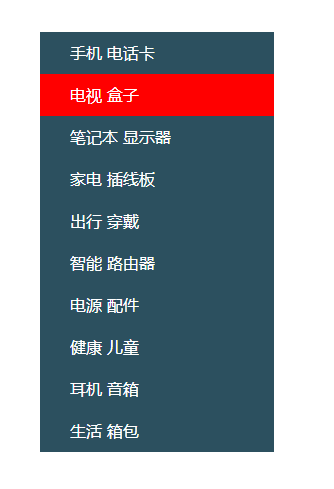

| 部分 | 参考值 |
| --- | --- |
| 外层 `.box` | 宽 234px、高 420px |
| 每个链接 | 宽 234px、高 42px、`display: block;` |
| 默认背景 | `#2c505f` |
| 文字 | 白色、14px、无下划线 |
| 文字位置 | `text-indent: 30px;`、行高 42px |
| 悬停 | 背景红色 |

配套 `小米侧边导航.html`：

```html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    .box {
      width: 234px;
      height: 420px;
      /* background-color: pink; */
    }

    .box a {
      /* 需要a标签这个行内元素设置宽高，需要转换成：块级元素或者行内块元素 */
      display: block;
      width: 234px;
      height: 42px;
      background-color: #2c505f;
      color: #fff;
      font-size: 14px;
      /* 去除默认的下划线 */
      text-decoration: none;
      /* 每个a标签文字首行缩进 */
      text-indent: 30px;
      /* a标签中的文字垂直居中 */
      line-height: 42px;
    }

    /* 鼠标移入之后，让a底色变红 */
    .box a:hover {
      background-color: red;
    }

  </style>
</head>
<body>
  <div class="box">
    <!-- 一般导航点击能跳转，所以一般需要使用a标签完成 -->
    <a href="#">手机 电话卡</a>
    <a href="#">电视 盒子</a>
    <a href="#">笔记本 显示器</a>
    <a href="#">家电 插线板</a>
    <a href="#">出行 穿戴</a>
    <a href="#">智能 路由器</a>
    <a href="#">电源 配件</a>
    <a href="#">健康 儿童</a>
    <a href="#">耳机 音箱</a>
    <a href="#">生活 箱包</a>
  </div>
</body>
</html>
```

十条链接每条高 42px，合计 420px。检查链接是否各占一行、首行缩进 30px、单行文字垂直居中；鼠标移入任意一行，应只有该行背景变红。


### 6.3 小米快捷菜单导航（★★★★）

用深色通栏包住一条横向文字导航，内部采用固定宽度、水平居中的容器；这一步按原资料模仿，后续项目再展开这种结构。

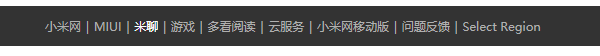

| 部分 | 参考值 |
| --- | --- |
| 外层 `.box` | 高 40px、背景 `#333` |
| 内层 `.container` | 宽 1226px、高 40px、`margin: 0 auto;` |
| 导航链接 | 12px、`#b0b0b0`、行高 40px、无下划线 |
| 链接悬停 | 文字变为 `#fff` |
| 分隔符 span | 12px、`#b0b0b0` |

配套 `小米快捷菜单导航.html`：

```html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    .box {
      height: 40px;
      background-color: #333;
    }

    /* 在后期项目项目中，会设置一个宽度固定并且水平居中的盒子包住内容，限定内部元素的范围（后面项目中会解释，同学们先以模仿为主） */
    .box .container {
      width: 1226px;
      height: 40px;
      /* background-color: pink; */
      margin: 0 auto;
    }

    .box .container a {
      text-decoration: none;
      line-height: 40px;
      font-size: 12px;
      color: #b0b0b0;
    }
    
    .box .container a:hover {
      color: #fff;
    }

    .box .container span {
      color: #b0b0b0;
      font-size: 12px;
    }
  </style>
</head>
<body>
  <div class="box">
    <div class="container">
      <a href="#">小米网</a>
      <span>|</span>
      <a href="#">MIUI</a>
      <span>|</span>
      <a href="#">米聊</a>
      <span>|</span>
      <a href="#">游戏</a>
      <span>|</span>
      <a href="#">多看阅读</a>
      <span>|</span>
      <a href="#">云服务</a>
      <span>|</span>
      <a href="#">小米网移动版</a>
      <span>|</span>
      <a href="#">问题反馈</a>
      <span>|</span>
      <a href="#">Select Region</a>
    </div>
  </div>
</body>
</html>
```

检查深灰背景是否铺满外层可用宽度，内层 1226px 容器是否居中，文字是否位于 40px 高的导航条中央；悬停时只改变当前链接的文字颜色，分隔线保留原色。测试固定宽度的居中效果时，浏览器应有足够宽度容纳内层容器。

### 6.4 资料中的练习顺序

先对照讲义整理当天的 XMind，再练习课堂代码直到能独立写出；跟随案例思路完成两个必做导航，有时间再选择 1～2 个选做练习。遇到效果不一致时，先用 Chrome 检查对应元素、匹配规则和最终属性，再回到源文件修改。
